# Klasifikasi Penggunaan dan Tutupan Lahan (Land Use / Land Cover)
### Citra Sentinel-2A + Algoritma Naive Bayes & K-Nearest Neighbors (KNN)

**Mata Kuliah:** Penambangan Data Sains (*Data Mining*)

---

## 1. Business Understanding (Pemahaman Bisnis)

**Latar Belakang**
Pemetaan tutupan lahan (*Land Cover*) sangat krusial untuk berbagai kepentingan analisis ruang, pengelolaan lingkungan, hingga perencanaan kota. Proses klasifikasi citra satelit multispektral (seperti Sentinel-2A) secara manual memakan waktu yang sangat lama. Oleh karena itu, kita memanfaatkan *Machine Learning* untuk mendeteksi secara otomatis.

**Tujuan**
1. Membangun model machine learning untuk mengklasifikasikan wilayah menjadi beberapa kelas (seperti Sawah, Bangunan, Mangrove, Hutan, Laut, dan Danau).
2. Membandingkan performa antara metode **Naive Bayes** dan **K-Nearest Neighbors (KNN)**.
3. Memvisualisasikan keseluruhan hasil klasifikasi/digitasi yang terpetakan ke dalam *interactive map* (Folium).


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import geopandas as gpd
import warnings
warnings.filterwarnings('ignore')

# Machine Learning Modules
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


---
## 2. Data Understanding (Pengumpulan & Pemahaman Data)
Kita akan memuat dataset citra satelit hasil ekstraksi (berisi nilai band spektral asli dan indeks turunan seperti NDVI, NDWI, dll).


In [4]:
# Memuat dataset
df = pd.read_csv('piksel_s2_JTM.csv')

print(f"Jumlah baris (piksel): {df.shape[0]}")
print(f"Jumlah kolom (fitur): {df.shape[1]}")
df.head()


Jumlah baris (piksel): 631268
Jumlah kolom (fitur): 19


,poligon_id,poligon_no,sampel_id,tile_id,label,label_teks,px_row,px_col,lon,lat,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI
0,Sawah_0000,0,0,x570_y-42,1,Sawah,374,119,114.100652,-8.312431,366.0,532.0,332.0,2903.0,1310.0,0.794745,-0.690247,-0.422367,-0.378115
1,Sawah_0000,0,0,x570_y-42,1,Sawah,375,119,114.100653,-8.312521,457.0,587.0,375.0,3125.0,1448.0,0.785714,-0.683728,-0.423096,-0.366718
2,Sawah_0000,0,0,x570_y-42,1,Sawah,375,120,114.100743,-8.312520,440.0,572.0,349.0,3015.0,1448.0,0.792509,-0.681071,-0.433663,-0.351109
3,Sawah_0000,0,0,x570_y-42,1,Sawah,375,121,114.100834,-8.312519,427.0,552.0,335.0,3020.0,1432.0,0.800298,-0.690929,-0.443548,-0.356694
4,Sawah_0000,0,0,x570_y-42,1,Sawah,375,122,114.100925,-8.312519,465.0,599.0,354.0,3315.0,1432.0,0.807032,-0.693919,-0.410143,-0.396672


---
## 3. Exploratory Data Analysis (EDA)
Melihat distribusi kelas dan perbandingan karakteristik beberapa indeks spektral antar kelas.


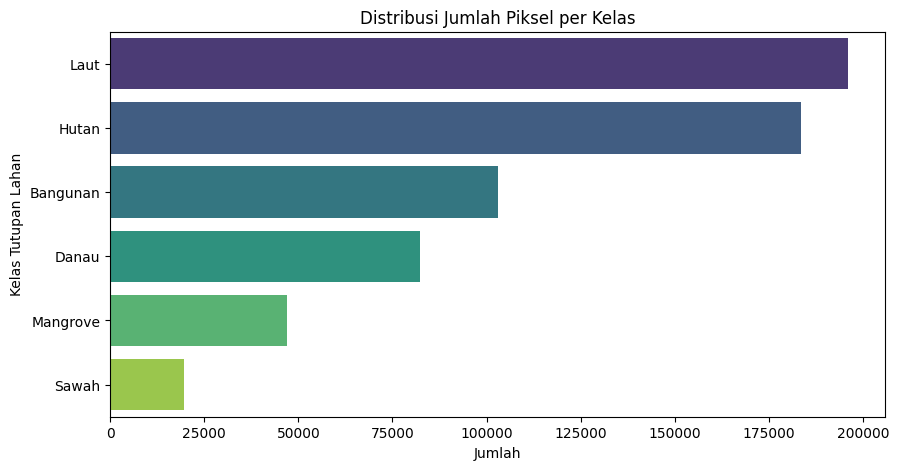

In [5]:
# Distribusi Kelas
plt.figure(figsize=(10, 5))
sns.countplot(y='label_teks', data=df, palette='viridis', order=df['label_teks'].value_counts().index)
plt.title('Distribusi Jumlah Piksel per Kelas')
plt.xlabel('Jumlah')
plt.ylabel('Kelas Tutupan Lahan')
plt.show()


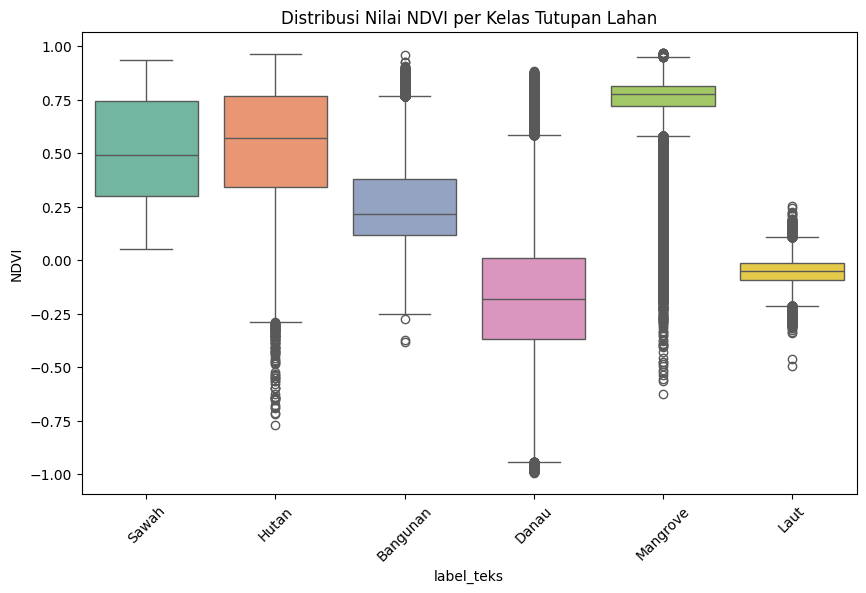

In [6]:
# Boxplot NDVI (Kerapatan Vegetasi) per Kelas
plt.figure(figsize=(10, 6))
sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')
plt.title('Distribusi Nilai NDVI per Kelas Tutupan Lahan')
plt.xticks(rotation=45)
plt.show()


---
## 4. Preprocessing Data
Membagi data menjadi variabel fitur (X) dan target (y), memisahkan data *training* dan *testing*, lalu melakukan standarisasi (*scaling*).


In [7]:
# 1. Menentukan Fitur (X) dan Target (y)
# Kita gunakan Band (B02, B03, B04, B08, B11) dan Indeks (NDVI, NDWI, MNDWI, NDBI)
fitur = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']

# Drop NaN jika ada
df_bersih = df.dropna(subset=fitur + ['label_teks']).copy()

X = df_bersih[fitur]
y = df_bersih['label_teks']

# 2. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standarisasi Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Jumlah Data Latih: {X_train.shape[0]}")
print(f"Jumlah Data Uji: {X_test.shape[0]}")


Jumlah Data Latih: 505014
Jumlah Data Uji: 126254


---
## 5. Pemodelan (Modeling & Evaluasi)
### 5.1 Naive Bayes (Gaussian)


In [8]:
# Inisialisasi dan Pelatihan Model
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# Prediksi
y_pred_nb = nb_model.predict(X_test_scaled)

# Evaluasi
print("=== HASIL EVALUASI NAIVE BAYES ===")
print(f"Akurasi : {accuracy_score(y_test, y_pred_nb)*100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_nb))


=== HASIL EVALUASI NAIVE BAYES ===
Akurasi : 73.56%

Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.61      0.71      0.66     20604
       Danau       0.81      0.66      0.73     16449
       Hutan       0.75      0.56      0.64     36702
        Laut       0.93      0.96      0.95     39200
    Mangrove       0.44      0.88      0.59      9397
       Sawah       0.37      0.19      0.25      3902

    accuracy                           0.74    126254
   macro avg       0.65      0.66      0.63    126254
weighted avg       0.76      0.74      0.73    126254



### 5.2 K-Nearest Neighbors (KNN)


In [9]:
# Inisialisasi dan Pelatihan Model (misal k=5)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# Prediksi
y_pred_knn = knn_model.predict(X_test_scaled)

# Evaluasi
print("=== HASIL EVALUASI K-NEAREST NEIGHBORS (KNN) ===")
print(f"Akurasi : {accuracy_score(y_test, y_pred_knn)*100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_knn))


=== HASIL EVALUASI K-NEAREST NEIGHBORS (KNN) ===
Akurasi : 88.52%

Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.76      0.73      0.75     20604
       Danau       0.92      0.87      0.89     16449
       Hutan       0.84      0.89      0.86     36702
        Laut       0.99      1.00      1.00     39200
    Mangrove       0.93      0.90      0.91      9397
       Sawah       0.65      0.55      0.60      3902

    accuracy                           0.89    126254
   macro avg       0.85      0.82      0.83    126254
weighted avg       0.88      0.89      0.88    126254



---
## 6. Visualisasi Peta Hasil Klasifikasi / Digitasi
Memetakan seluruh titik hasil digitasi ke dalam peta **Folium** menggunakan pendekatan *Convex Hull* agar peta berjalan dengan ringan dan keseluruhan area terlihat sebagai satu kesatuan poligon.


In [10]:
# Rekonstruksi Titik menjadi Poligon (Convex Hull)
gdf = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326"
)

# Dissolve dan pastikan fitur terjaga
polygons = gdf.dissolve(by='poligon_id', aggfunc='first').reset_index()
polygons['geometry'] = polygons['geometry'].convex_hull
polygons = polygons[~polygons['geometry'].is_empty]

# Membuat Peta
map_center = [df['lat'].mean(), df['lon'].mean()]

m = folium.Map(
    location=map_center, 
    zoom_start=10, 
    tiles='https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}',
    attr='Google'
)

# Layer Tambahan
folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    attr='Google',
    name='Google Satellite',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri',
    name='Esri Satellite',
    overlay=False,
    control=True
).add_to(m)

# Pewarnaan sesuai kelas
colors = {
    'Sawah': '#FFD92F',
    'Bangunan': '#E41A1C',
    'Mangrove': '#8E44AD',
    'Lahan Hijau': '#2E7D32',
    'Hutan': '#2E7D32',
    'Perairan Terbuka (Laut)': '#0D47A1',
    'Laut': '#0D47A1',
    'Danau': '#4FC3F7'
}

feature_groups = {}
for label in polygons['label_teks'].unique():
    label_str = str(label)
    feature_groups[label_str] = folium.FeatureGroup(name=label_str)
    m.add_child(feature_groups[label_str])

for idx, row in polygons.iterrows():
    label_str = str(row['label_teks'])
    color = colors.get(label_str, 'black')
    
    try:
        folium.GeoJson(
            data=row['geometry'].__geo_interface__,
            style_function=lambda x, c=color: {
                'fillColor': c,
                'color': c,
                'weight': 1,
                'fillOpacity': 0.7
            },
            tooltip=f"{label_str} (Poligon ID: {row['poligon_id']})"
        ).add_to(feature_groups[label_str])
    except Exception:
        pass

folium.LayerControl().add_to(m)

# Menampilkan peta
m



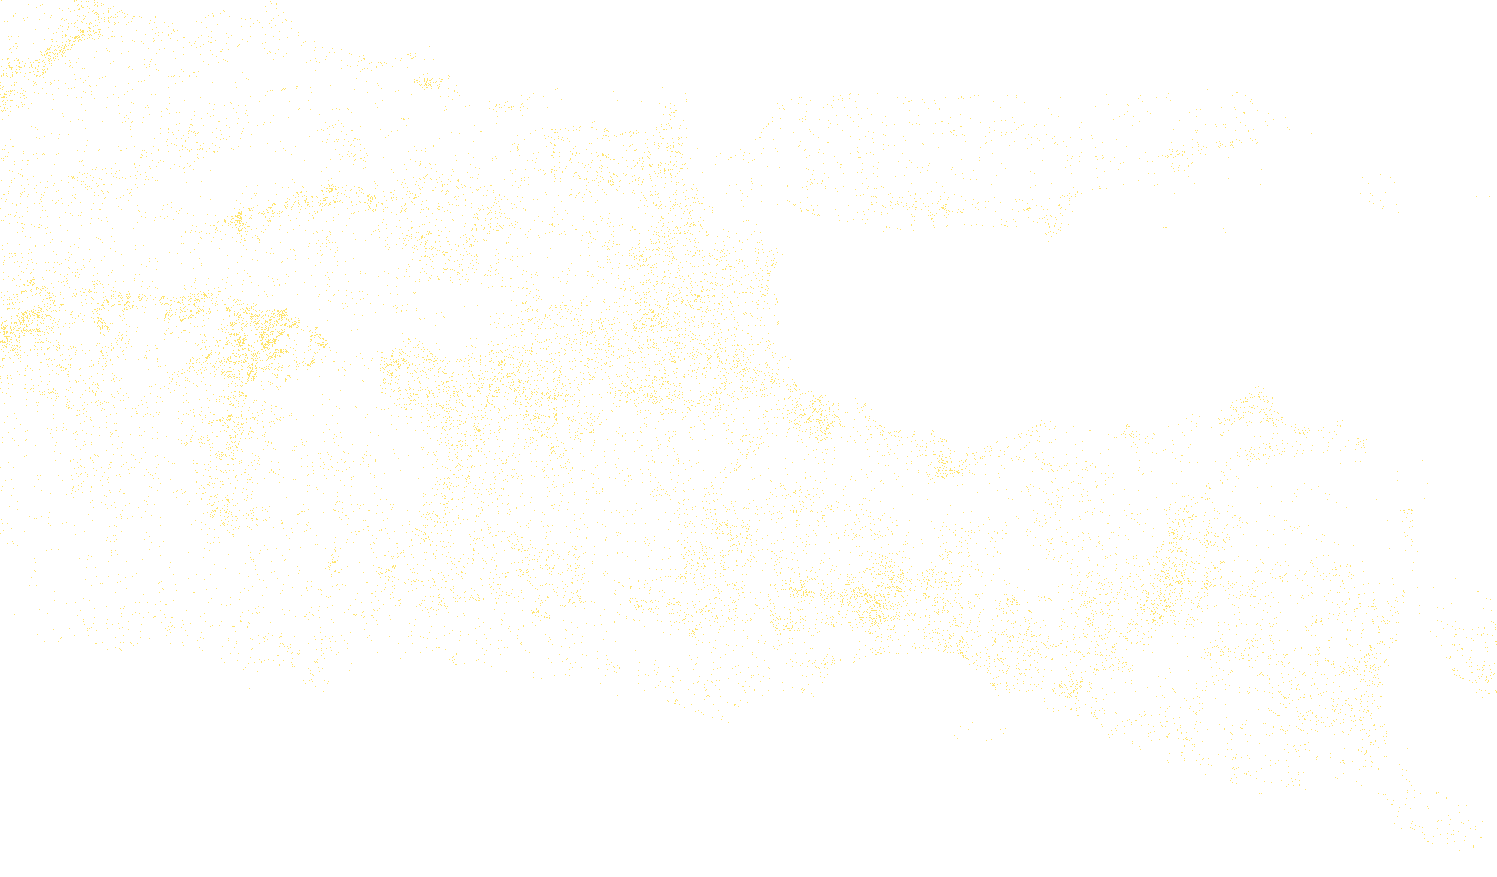
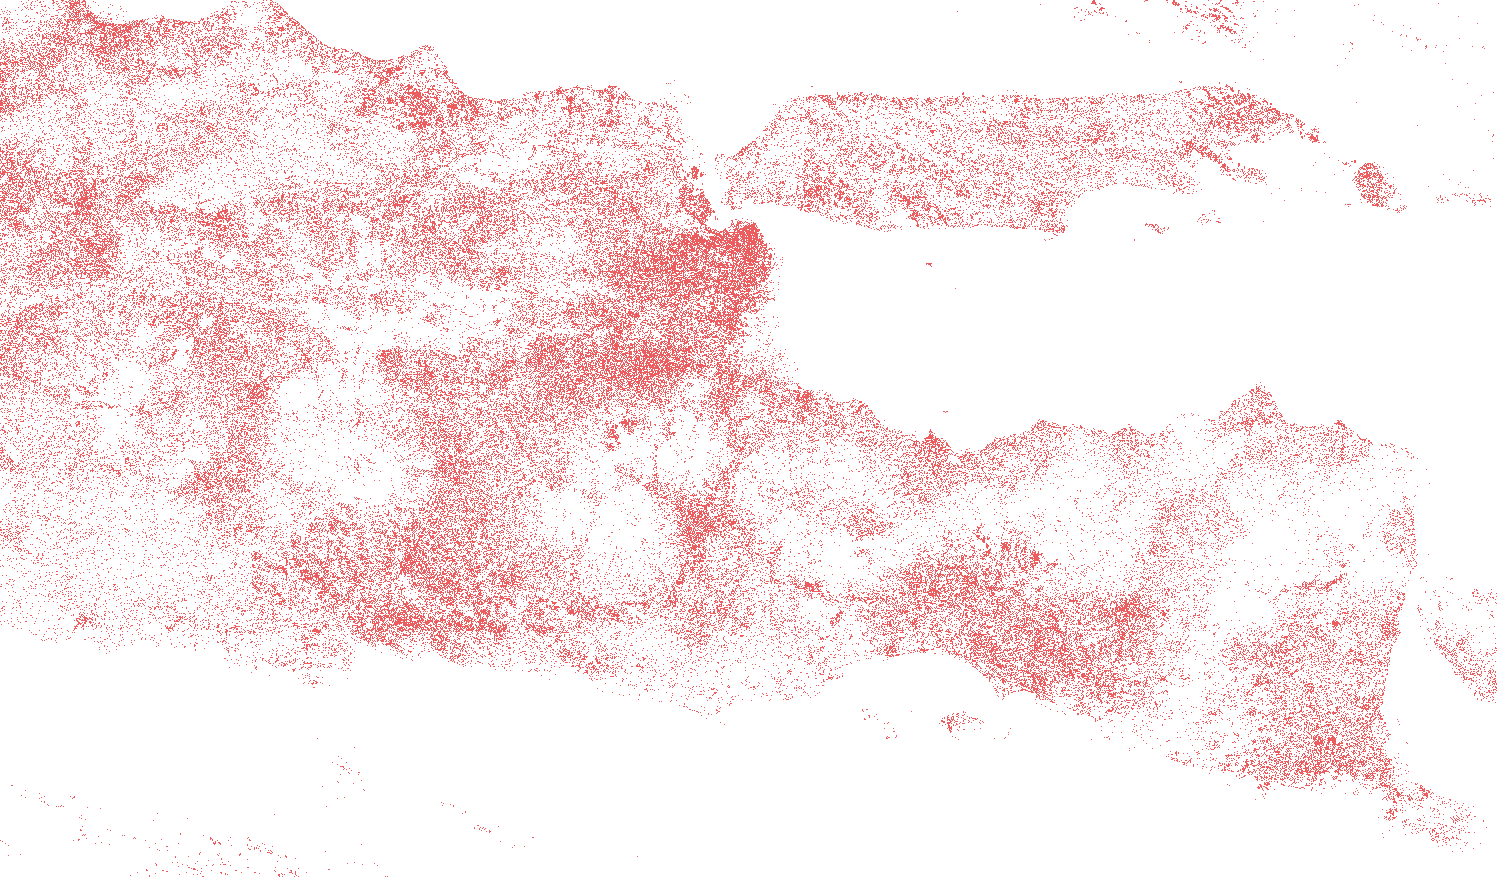
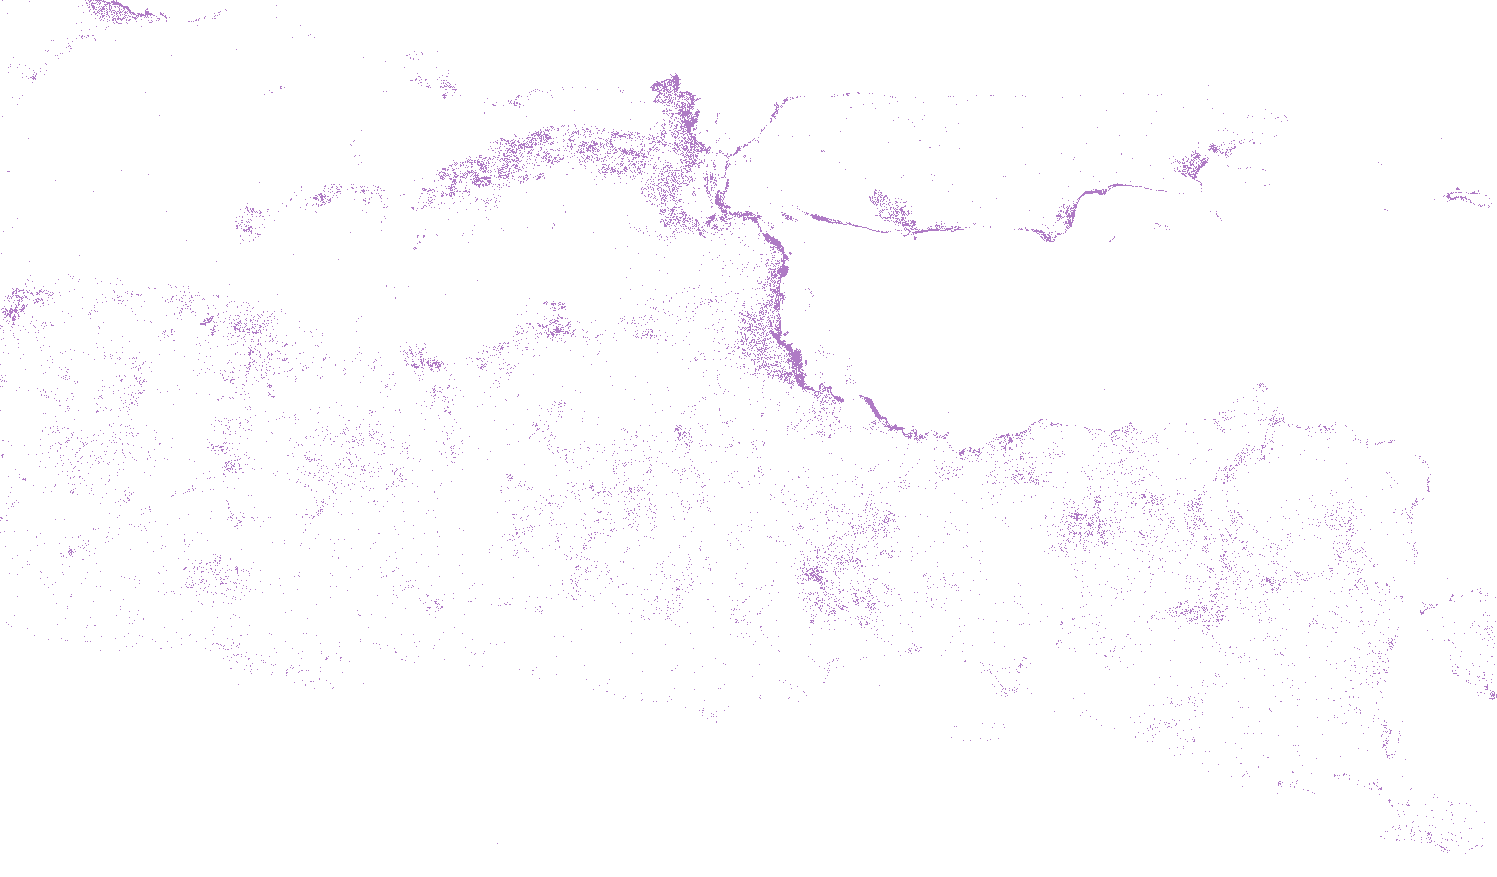
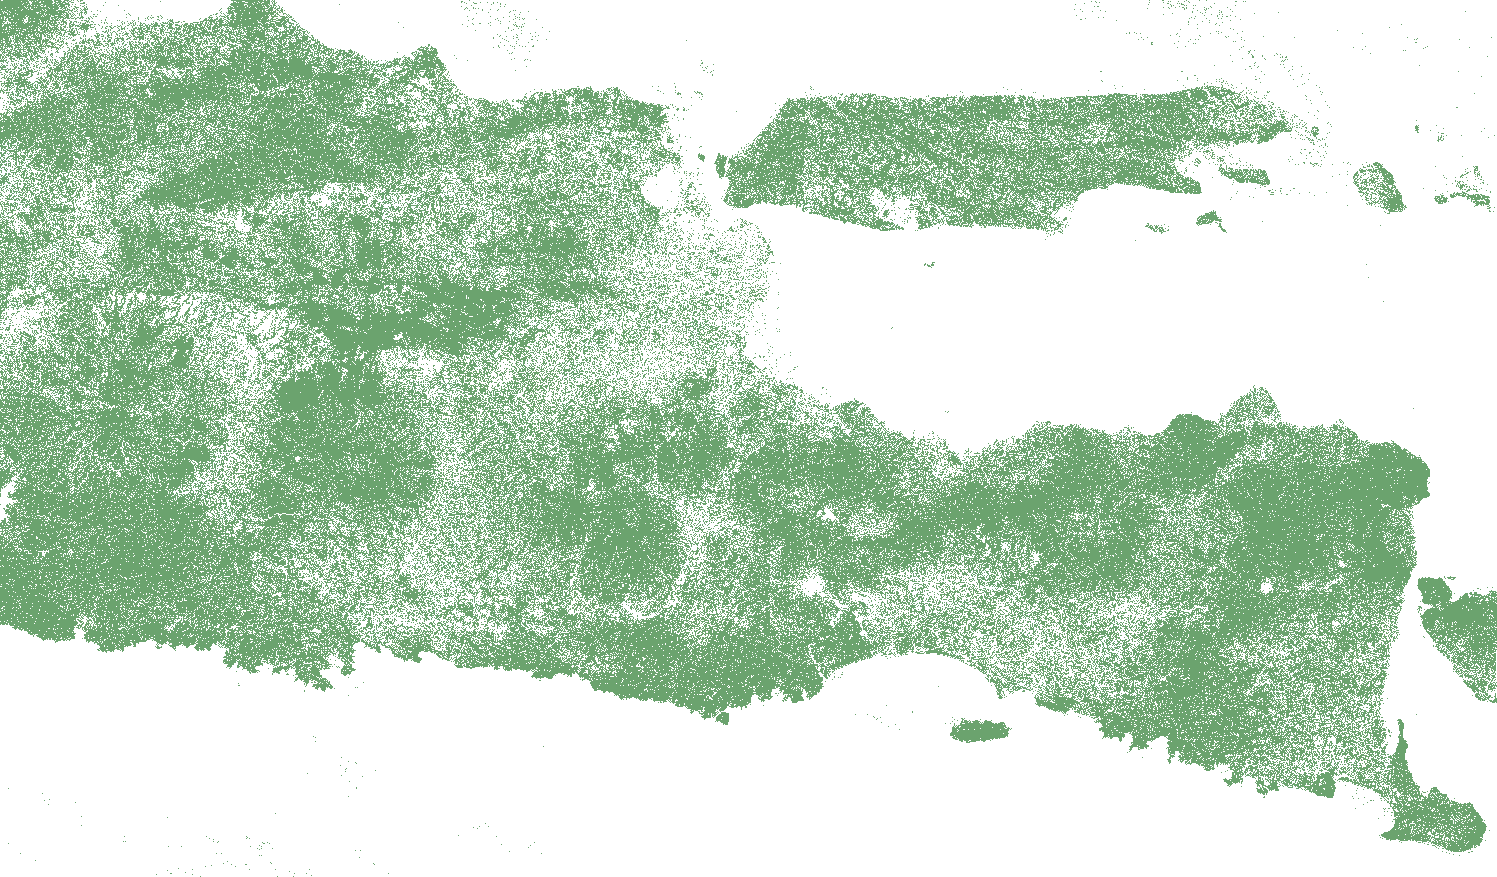
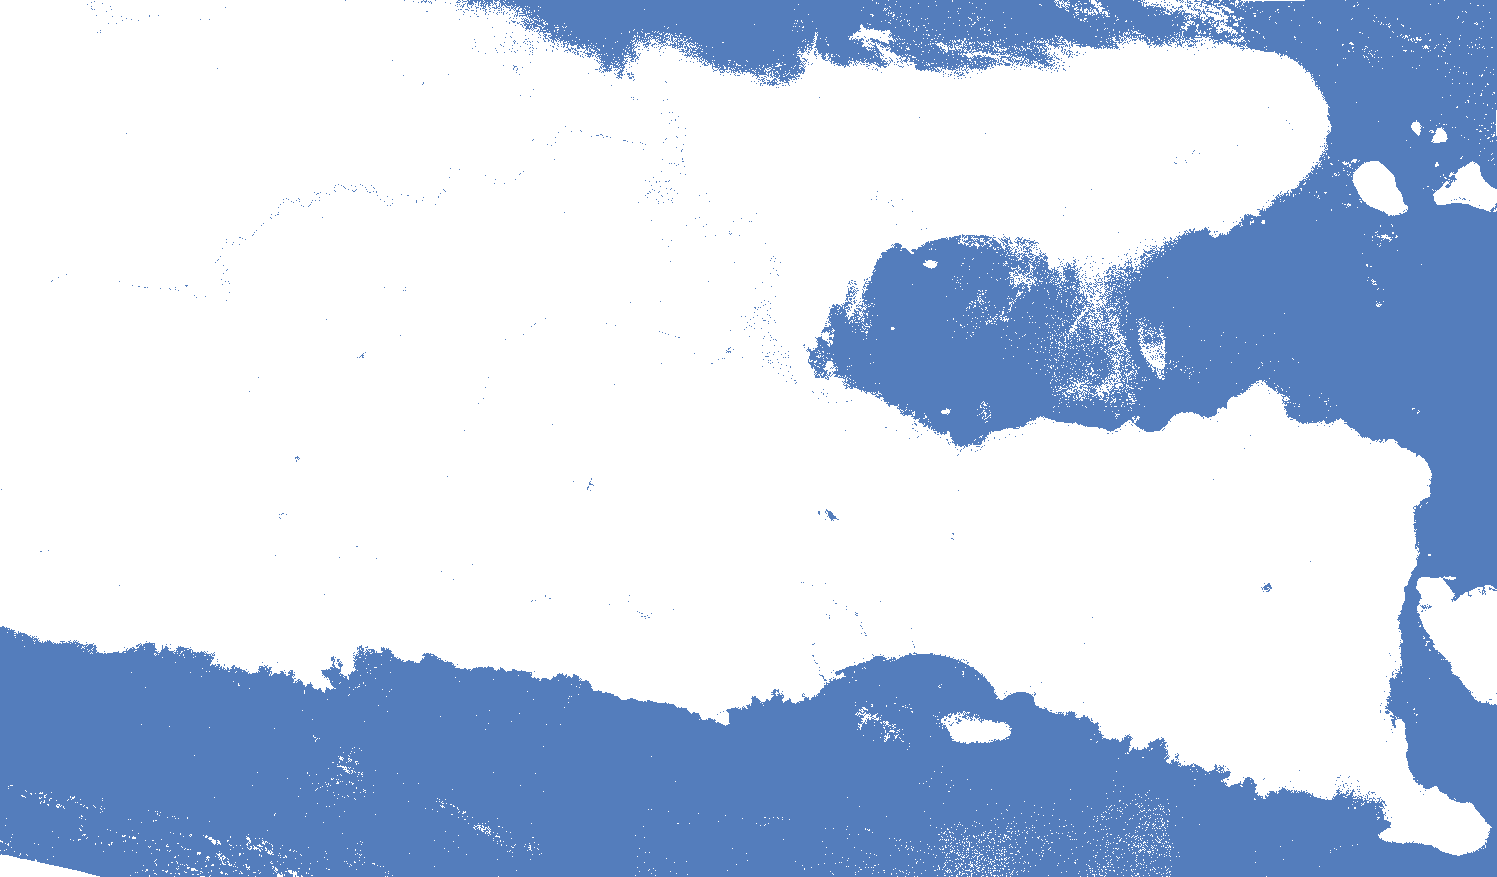
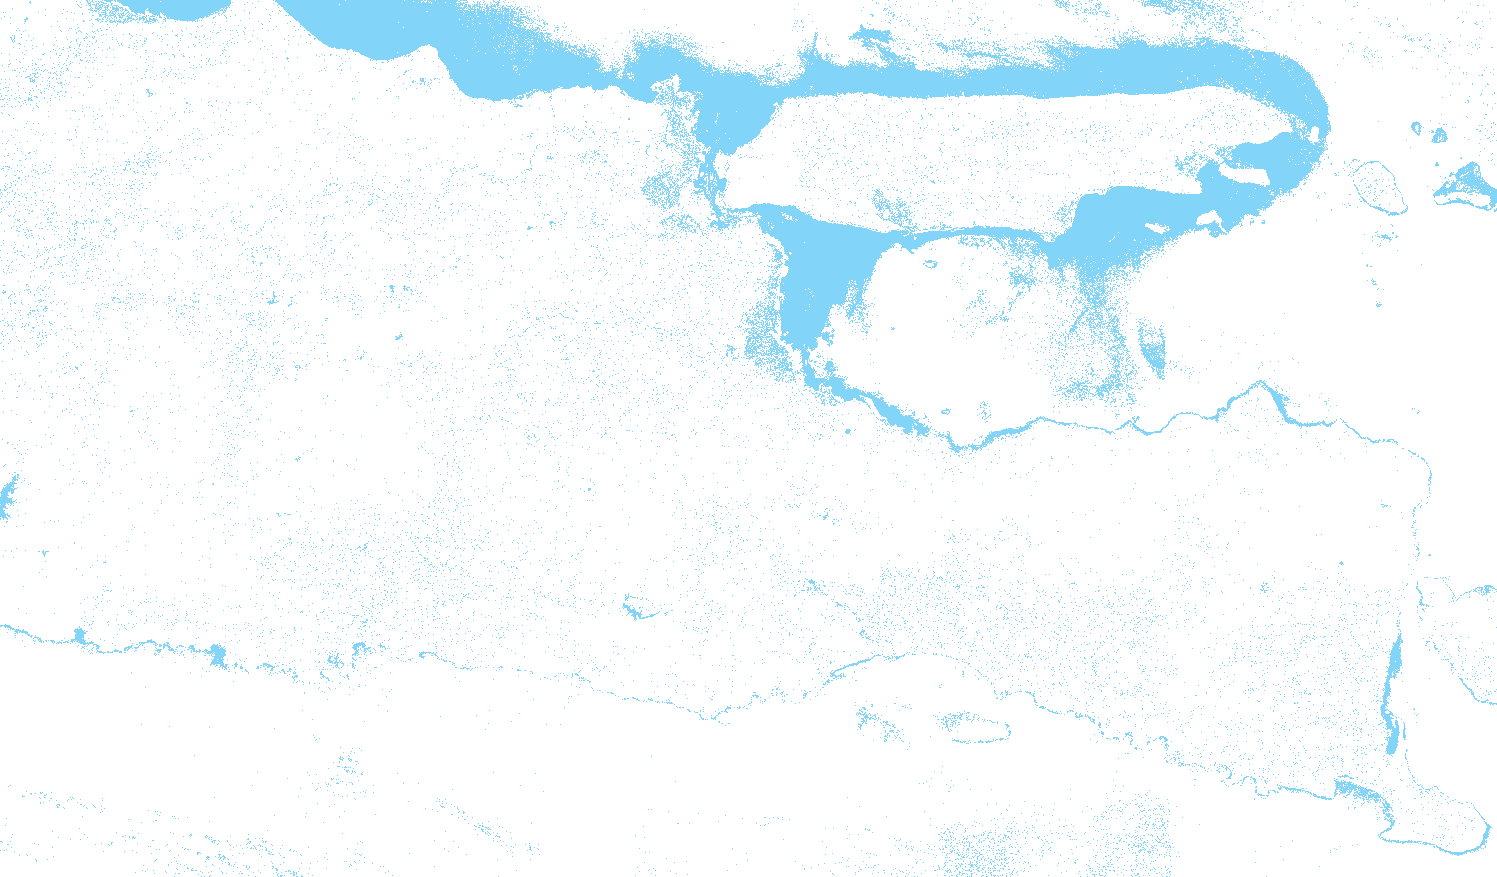

In [13]:
import os
import rasterio
import numpy as np
import folium
import openeo

# Fungsi pembantu: konversi kode warna hex (#RRGGBB) ke (R, G, B)
def hex_to_rgb(hex_code):
    hex_code = hex_code.lstrip('#')
    return tuple(int(hex_code[i:i+2], 16) for i in (0, 2, 4))

# Tentukan path raster wilayah utuh
FILE_RASTER = 'jatim_250m.tif' 

# 1. UNDUH DATA VIA OPENEO (MENGGUNAKAN BATCH JOB KARENA AREA BESAR)
if not os.path.exists(FILE_RASTER):
    print("Mengunduh komposit Jawa Timur via openEO Batch Job (Resolusi ~250m)...")
    try:
        # Hubungkan ke CDSE openEO
        connection = openeo.connect("https://openeo.dataspace.copernicus.eu").authenticate_oidc()
        
        # Bounding Box Kasar untuk wilayah Jawa Timur
        bbox_jatim = {
            "west": 110.89, "south": -8.84,
            "east": 114.63, "north": -6.65
        }
        
        cube = connection.load_collection(
            "SENTINEL2_L2A",
            spatial_extent=bbox_jatim,
            temporal_extent=["2024-08-01", "2024-08-31"], # atau rentang waktu yang diinginkan
            bands=['B02', 'B03', 'B04', 'B08', 'B11'],
            max_cloud_cover=30
        )
        
        # Agregasi waktu (Median) untuk membersihkan sisa awan
        cube = cube.median_time()
        
        # Turunkan resolusi spasial ke 0.0025 derajat (~250 meter)
        cube = cube.resample_spatial(resolution=0.0025, projection=4326)
        
        # Simpan hasil dalam format GeoTIFF
        cube = cube.save_result(format="GTiff")
        
        # Jalankan via Batch Job agar lolos limit 20.000 x 20.000 pixel
        print("Membuat batch job di openEO server...")
        job = cube.create_job(title="Jatim_Composite_250m")
        job.start_and_wait()
        
        # Unduh asset hasil job ke folder lokal
        results = job.get_results()
        results.download_file(FILE_RASTER)
        print("Unduhan batch job selesai dan tersimpan di:", FILE_RASTER)

    except Exception as e:
        print(f"Gagal memproses data openEO: {e}")

# 2. BACA RASTER DAN LAKUKAN PREDIKSI
if os.path.exists(FILE_RASTER):
    with rasterio.open(FILE_RASTER) as src:
        b2 = src.read(1).astype(float)
        b3 = src.read(2).astype(float)
        b4 = src.read(3).astype(float)
        b8 = src.read(4).astype(float)
        b11 = src.read(5).astype(float)
        
        bounds = src.bounds
        img_bounds = [[bounds.bottom, bounds.left], [bounds.top, bounds.right]]
        center_lat = (bounds.bottom + bounds.top) / 2
        center_lon = (bounds.left + bounds.right) / 2

    # Menghitung ulang Indeks Spektral
    e = 1e-9
    ndvi = (b8 - b4) / (b8 + b4 + e)
    ndwi = (b3 - b8) / (b3 + b8 + e)
    mndwi = (b3 - b11) / (b3 + b11 + e)
    ndbi = (b11 - b8) / (b11 + b8 + e)
    
    height, width = b2.shape
    
    # Ratakan (flatten) array 2D menjadi 1D
    features_stack = np.column_stack((
        b2.flatten(), b3.flatten(), b4.flatten(), b8.flatten(), b11.flatten(),
        ndvi.flatten(), ndwi.flatten(), mndwi.flatten(), ndbi.flatten()
    ))
    
    # Deteksi piksel valid (bukan padding 0 di luar daratan/laut peta)
    valid_mask = (b2.flatten() > 0)
    
    # Scaling fitur
    features_scaled = scaler.transform(features_stack)
    
    # Prediksi
    pred_1d = knn_model.predict(features_scaled)
    pred_2d = pred_1d.reshape((height, width))
    valid_2d = valid_mask.reshape((height, width))
    
    # 3. PLOTTING KE PETA FOLIUM
    m_full = folium.Map(
        location=[center_lat, center_lon], 
        zoom_start=8, 
        tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
        attr='Google Satellite'
    )
    
    # Buat Image Overlay untuk tiap kelas (layer toggleable)
    for label_str, hex_color in colors.items():
        rgba_img = np.zeros((height, width, 4), dtype=np.uint8)
        
        # Masking piksel prediksi & valid
        mask = (pred_2d == label_str) & valid_2d
        
        if np.any(mask):
            r, g, b = hex_to_rgb(hex_color)
            rgba_img[mask, 0] = r
            rgba_img[mask, 1] = g
            rgba_img[mask, 2] = b
            rgba_img[mask, 3] = 180  # Opacity layer
            
            folium.raster_layers.ImageOverlay(
                image=rgba_img,
                bounds=img_bounds,
                opacity=0.7,
                name=f"Sebaran {label_str}",
                show=True
            ).add_to(m_full)
    
    folium.LayerControl().add_to(m_full)
    display(m_full)
else:
    print("Tidak dapat menampilkan peta karena file raster tidak tersedia.")
